In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score

# Seed for Reproducibility
np.random.seed(42)
print("Libraries loaded successfully!")


Libraries loaded successfully!


In [2]:
# Synthetic clinical dataset of 35 patients : Drug Dosage vs Patient Recovery Index
n_samples = 35
dosage = np.sort(np.random.uniform(1.0, 10.0, n_samples)).reshape(-1, 1)

# Biological curve: peak recovery at 5.5 - 6.0 mg , after that drop to toxicity
recovery = -1.2 * (dosage ** 2) + 14.0 * dosage - 10.0 + np.random.normal(0, 3.2, size=dosage.shape)

print(f"Generated {n_samples} patient records.")
print("Sample Dosage (mg):", dosage[:3].flatten())
print("Sample Recovery Index:", recovery[:3].flatten())

Generated 35 patient records.
Sample Dosage (mg): [1.18526045 1.41805371 1.52275251]
Sample Recovery Index: [ 2.98702316 10.47150783  9.46731369]


In [3]:
# 1. Degree 1: Simple Linear Regression (Underfitting / High Bias)
model_deg1 = LinearRegression()
model_deg1.fit(dosage, recovery)
pred_deg1 = model_deg1.predict(dosage)

# 2. Degree 2: Optimal Quadratic Polynomial (Balanced Fit)
poly2 = PolynomialFeatures(degree=2, include_bias=False)
dosage_poly2 = poly2.fit_transform(dosage)
model_deg2 = LinearRegression()
model_deg2.fit(dosage_poly2, recovery)
pred_deg2 = model_deg2.predict(dosage_poly2)

# 3. Degree 9: High-Order Polynomial (Overfitting / High Variance)
model_deg9 = make_pipeline(PolynomialFeatures(degree=9, include_bias=False),
                           StandardScaler(),
                           LinearRegression())
model_deg9.fit(dosage, recovery)
pred_deg9 = model_deg9.predict(dosage)

print("All 3 models trained successfully!")

All 3 models trained successfully!


In [4]:
print("=" * 65)
print(f"{'Model Complexity':<30} | {'MSE (Lower is better)':<22} | {'R2 Score':<10}")
print("=" * 65)
print(f"{'Degree 1 (Linear Underfit)':<30} | {mean_squared_error(recovery, pred_deg1):<22.3f} | {r2_score(recovery, pred_deg1):<10.3f}")
print(f"{'Degree 2 (Optimal Quadratic)':<30} | {mean_squared_error(recovery, pred_deg2):<22.3f} | {r2_score(recovery, pred_deg2):<10.3f}")
print(f"{'Degree 9 (Complex Overfit)':<30} | {mean_squared_error(recovery, pred_deg9):<22.3f} | {r2_score(recovery, pred_deg9):<10.3f}")
print("=" * 65)

print("\nLearned Weights for Degree 2:")
print(f"theta_0 (Intercept): {model_deg2.intercept_[0]:.4f}")
print(f"theta_1 (Linear):    {model_deg2.coef_[0][0]:.4f}")
print(f"theta_2 (Quadratic): {model_deg2.coef_[0][1]:.4f}")

Model Complexity               | MSE (Lower is better)  | R2 Score  
Degree 1 (Linear Underfit)     | 62.809                 | 0.079     
Degree 2 (Optimal Quadratic)   | 9.461                  | 0.861     
Degree 9 (Complex Overfit)     | 5.483                  | 0.920     

Learned Weights for Degree 2:
theta_0 (Intercept): -9.7224
theta_1 (Linear):    13.8572
theta_2 (Quadratic): -1.1858


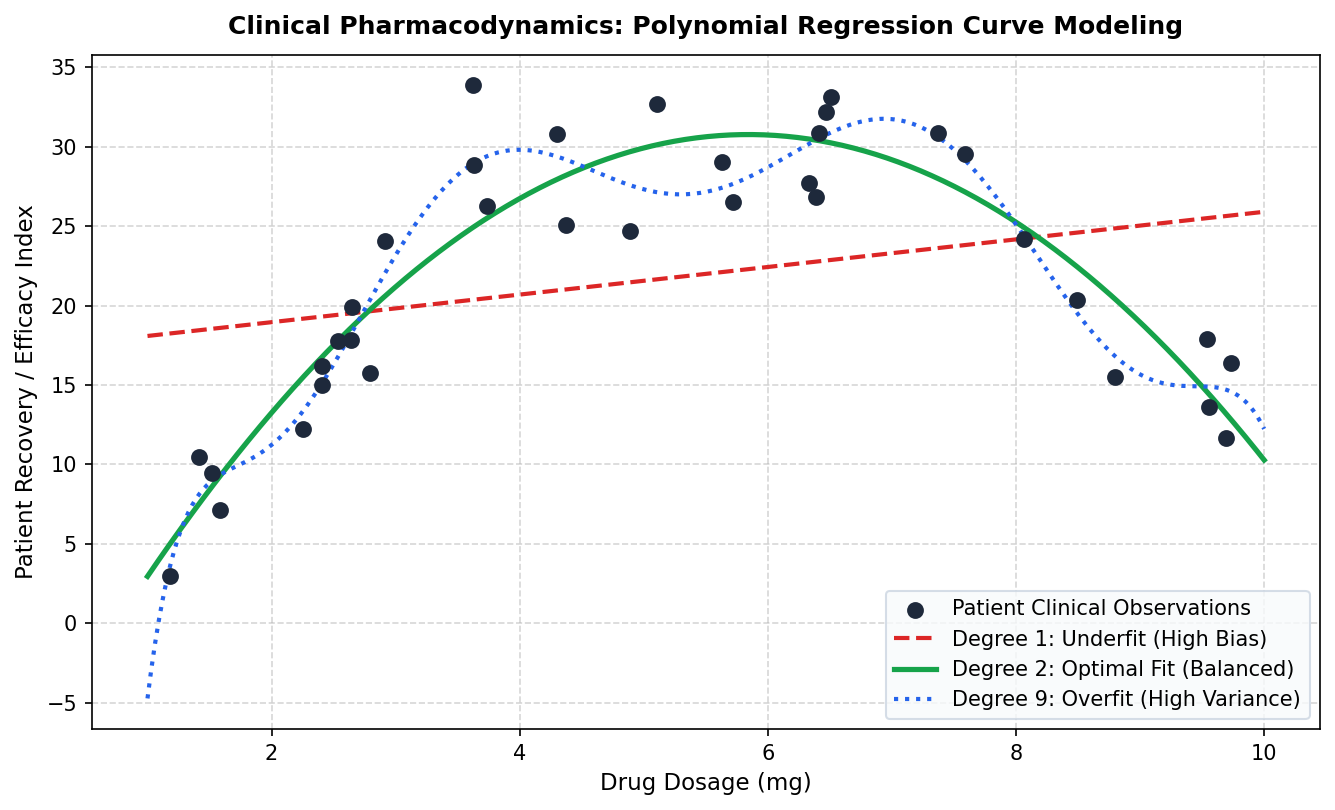

In [5]:
X_grid = np.linspace(1.0, 10.0, 300).reshape(-1, 1)

plt.figure(figsize=(9, 5.5), dpi=150)
plt.scatter(dosage, recovery, color='#1e293b', s=50, label='Patient Clinical Observations', zorder=3)
plt.plot(X_grid, model_deg1.predict(X_grid), color='#dc2626', linestyle='--', linewidth=2, label='Degree 1: Underfit (High Bias)')
plt.plot(X_grid, model_deg2.predict(poly2.transform(X_grid)), color='#16a34a', linewidth=2.5, label='Degree 2: Optimal Fit (Balanced)')
plt.plot(X_grid, model_deg9.predict(X_grid), color='#2563eb', linestyle=':', linewidth=2, label='Degree 9: Overfit (High Variance)')

plt.title('Clinical Pharmacodynamics: Polynomial Regression Curve Modeling', fontsize=12, fontweight='bold', pad=10)
plt.xlabel('Drug Dosage (mg)', fontsize=11)
plt.ylabel('Patient Recovery / Efficacy Index', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(frameon=True, facecolor='#f8fafc', edgecolor='#cbd5e1')
plt.tight_layout()
plt.show()